# AETHER — Benchmark Comparison

Compares AETHER against reference models on the same split. Produce the inputs
with:

```bash
python -m neoantigen.benchmark.run \
    --data_dir data/mhcattnnet/classI_peptide_split --split test \
    --out_dir outputs/benchmarks \
    --include aether=outputs/classI_peptide_split/test_predictions.csv
```

Read the baselines as three separate questions:

- **`majority`, `allele_prior`, `allele_length_prior`** never look at the
  peptide. They predict from label frequencies alone. On a 77%-positive set with
  long-tailed allele support they score far above 0.5 — so the gap between
  AETHER and `allele_length_prior` is the first thing to check.
- **`pssm`, `blosum_lr`** are the classical approaches. A 650M-parameter
  transformer should clear them comfortably.
- **`esm2_probe`** is the architecture ablation: the same frozen ESM2
  embeddings, mean-pooled, with a linear model on top. The gap between it and
  AETHER is what the cross-attention and attention pooling actually buy.

Compare on **`auroc_common`** — the subset every method scored — not `auroc`,
since methods decline different rows.

In [1]:
from pathlib import Path
import json
import logging
import os
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# matplotlib reports a missing font through the logging module rather than
# warnings, so filterwarnings alone never silences "findfont: Font family
# 'Arial' not found".
warnings.filterwarnings("ignore", message=".*findfont.*")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

# ---------------------------------------------------------------------
# plot style
# ---------------------------------------------------------------------
# Arial is the house font, but it ships with no Linux distribution and is not
# installed on this machine. Declaring a fallback chain means the figures use
# Arial wherever it exists and a metrically similar sans elsewhere, rather than
# matplotlib silently substituting whatever it has. Liberation Sans and Nimbus
# Sans share Arial's metrics, so text occupies the same space; DejaVu Sans is
# matplotlib's bundled last resort and is slightly wider.
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = [
    "Arial", "Liberation Sans", "Nimbus Sans", "Helvetica", "DejaVu Sans",
]
mpl.rcParams["font.size"] = 10
DPI = 600
FIGSIZE = (6, 3.8)   # every figure stands alone; no subplots

BAR_COLOR = "#4b5563"
LIGHT_BAR_COLOR = "#d1d5db"
REF_LINE = "#6b7280"
GRID_COLOR = "#f0f0f0"

# ink scale for text that is not an axis label
INK = "#111827"
INK_SOFT = "#4b5563"
INK_MUTED = "#6b7280"

TAB = {"blue": "#4e79a7", "orange": "#f28e2b", "red": "#e15759", "teal": "#76b7b2",
       "green": "#59a14f", "yellow": "#edc948", "purple": "#b07aa1",
       "pink": "#ff9da7", "brown": "#9c755f", "gray": "#bab0ac"}

# roles, so a plot is written against what the color means
BINDER, NON_BINDER = TAB["blue"], TAB["orange"]
TRAIN_COLOR, VAL_COLOR = TAB["blue"], TAB["red"]
CLASS_COLORS = {"Binder": BINDER, "Non-binder": NON_BINDER}


def new_fig(figsize=FIGSIZE):
    """one standalone figure with its axes styled"""
    fig, ax = plt.subplots(figsize=figsize)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color=GRID_COLOR, linewidth=0.6)
    ax.set_axisbelow(True)
    return fig, ax


def save_fig(fig, name):
    """600 dpi png into figures/, cropped to everything drawn"""
    path = FIG_DIR / name
    fig.savefig(path, dpi=DPI, bbox_inches="tight")
    print(f"saved {path}")


def left_legend(ax, handles, title, anchor):
    """left-aligned legend outside the axes; call again to stack another one below"""
    if ax.get_legend() is not None:
        previous = ax.get_legend()
        ax.add_artist(previous)
        previous.set_clip_on(False)
    legend = ax.legend(handles=handles, title=title, frameon=False,
                       bbox_to_anchor=anchor, loc="upper left")
    legend._legend_box.align = "left"
    legend.get_title().set_ha("left")
    return legend


def class_handles():
    return [Patch(facecolor=c, label=k) for k, c in CLASS_COLORS.items()]


# ---------------------------------------------------------------------
# paths, relative to this notebook
# ---------------------------------------------------------------------
FIG_DIR = Path.cwd()
REPO = FIG_DIR
while REPO != REPO.parent and not (REPO / "data").is_dir():
    REPO = REPO.parent
print("repo:", REPO)

# Colors follow the method, never its rank, so a method keeps its color when the
# ordering changes between splits.
METHOD_COLORS = {
    "aether":              TAB["blue"],
    "esm2_probe":          TAB["orange"],
    "pssm":                TAB["green"],
    "blosum_lr":           TAB["teal"],
    "allele_length_prior": TAB["red"],
    "allele_prior":        TAB["purple"],
    "length_prior":        TAB["yellow"],
    "majority":            TAB["gray"],
    "pepmhc_archive":      TAB["brown"],
    "mhcflurry":           TAB["pink"],
    "netmhcpan":           BAR_COLOR,
}
METHOD_LABELS = {
    "aether":              "AETHER",
    "esm2_probe":          "ESM2 linear probe",
    "pssm":                "PSSM (per allele)",
    "blosum_lr":           "BLOSUM + logistic",
    "allele_length_prior": "Allele×length prior",
    "allele_prior":        "Allele prior",
    "length_prior":        "Length prior",
    "majority":            "Majority class",
    "pepmhc_archive":      "PepMHC (archived)",
    "mhcflurry":           "MHCflurry",
    "netmhcpan":           "NetMHCpan",
}

def mcolor(m):
    return METHOD_COLORS.get(m, BAR_COLOR)

def mlabel(m):
    return METHOD_LABELS.get(m, m)

repo: /home/vivian.chu/AETHER


In [2]:
# ---------------------------------------------------------------------
# point this at your benchmark output
# ---------------------------------------------------------------------
BENCH_DIR = Path(os.environ.get("AETHER_BENCH_DIR") or (REPO / "outputs" / "benchmarks"))

if not BENCH_DIR.exists():
    raise SystemExit(f"No benchmark output at {BENCH_DIR}. "
                     "Run `python -m neoantigen.benchmark.run ...` first.")

summary = pd.read_csv(BENCH_DIR / "benchmark_summary.csv").set_index("method")
meta = json.loads((BENCH_DIR / "benchmark_meta.json").read_text())

preds = {}
for path in sorted(BENCH_DIR.glob("*_predictions.csv")):
    name = path.name.replace("_predictions.csv", "")
    preds[name] = pd.read_csv(path)

RANK_COL = "auroc_common" if "auroc_common" in summary.columns else "auroc"
order = summary.sort_values(RANK_COL, ascending=False).index.tolist()

print(f"{len(preds)} methods | split={meta['split']} | "
      f"common subset = {meta['n_common']:,} rows")
summary.sort_values(RANK_COL, ascending=False).round(4)

9 methods | split=test | common subset = 34,803 rows


,n_total,n_scored,coverage,auroc,auprc,positive_rate,auroc_common,auprc_common
method,,,,,,,,
aether,35339.0,35339.0,1.0000,0.9639,0.9877,0.7577,0.9640,0.9875
mhcflurry,35339.0,34803.0,0.9848,0.9410,0.9803,0.7547,0.9410,0.9803
pssm,35339.0,35339.0,1.0000,0.9107,0.9696,0.7577,0.9178,0.9713
blosum_lr,35339.0,35339.0,1.0000,0.8677,0.9517,0.7577,0.8679,0.9511
esm2_probe,35339.0,35339.0,1.0000,0.8673,0.9528,0.7577,0.8662,0.9517
allele_length_prior,35339.0,35339.0,1.0000,0.8619,0.9521,0.7577,0.8594,0.9504
allele_prior,35339.0,35339.0,1.0000,0.8186,0.9304,0.7577,0.8178,0.9291
pepmhc_archive,35339.0,35339.0,1.0000,0.6149,0.8036,0.7577,0.6122,0.7994
majority,35339.0,35339.0,1.0000,0.5000,0.7577,0.7577,0.5000,0.7547


## AUROC Comparison

The dashed line is the strongest baseline that never reads the peptide. Anything
at or below it has not learned binding chemistry — only which alleles are
well represented and how often they bind.

saved /home/vivian.chu/AETHER/figures/benchmark_auroc.png


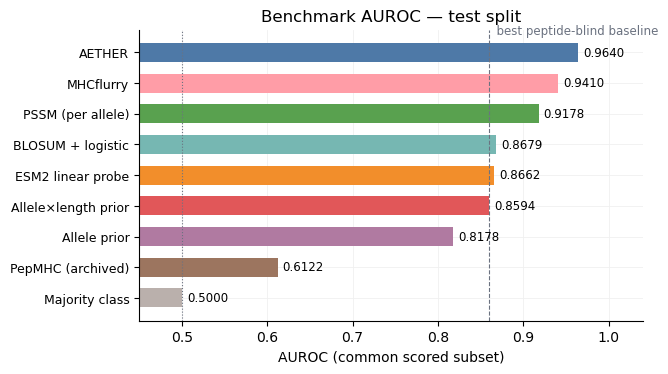

In [3]:
fig, ax = new_fig((6.5, max(3, 0.42 * len(order))))

vals = summary.loc[order, RANK_COL]
y = np.arange(len(order))[::-1]
ax.barh(y, vals, height=0.62, color=[mcolor(m) for m in order])
for yi, (m, v) in zip(y, vals.items()):
    ax.text(v + 0.006, yi, f"{v:.4f}", va="center", fontsize=8.5)

# the no-peptide ceiling
blind = [m for m in ("allele_length_prior", "allele_prior", "length_prior",
                     "majority") if m in summary.index]
if blind:
    ceiling = summary.loc[blind, RANK_COL].max()
    ax.axvline(ceiling, color=REF_LINE, linestyle="--", linewidth=0.8)
    ax.text(ceiling, len(order) - 0.4, "  best peptide-blind baseline",
            fontsize=8.5, color=REF_LINE, ha="left")

ax.axvline(0.5, color=REF_LINE, linestyle=":", linewidth=0.8)
ax.set_yticks(y, [mlabel(m) for m in order], fontsize=9)
ax.set_xlabel("AUROC (common scored subset)")
ax.set_xlim(0.45, min(1.04, float(vals.max()) + 0.08))
ax.set_title(f"Benchmark AUROC — {meta['split']} split")

save_fig(fig, "benchmark_auroc.png")
plt.show()

## ROC Curves

Capped at the six strongest methods plus AETHER, because more than that on one
axes stops being readable.

saved /home/vivian.chu/AETHER/figures/benchmark_roc.png


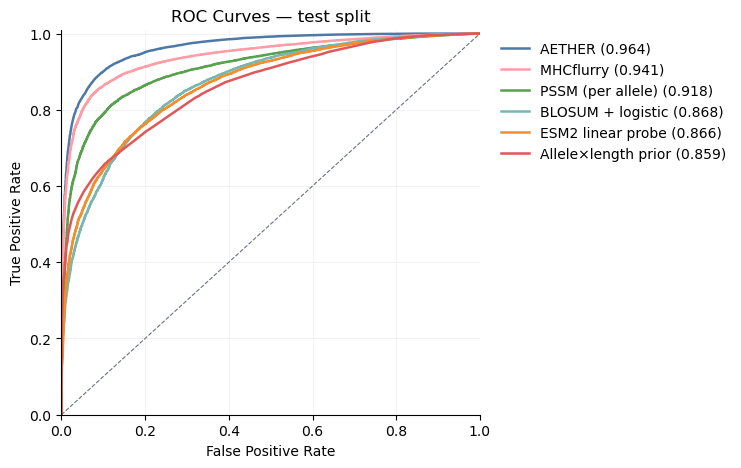

In [4]:
from sklearn.metrics import roc_auc_score, roc_curve

# Cap the overlay: more than ~6 curves on one axes stops being readable. Always
# keep AETHER in, whatever it ranked.
show = [m for m in order[:6] if m in preds]
if "aether" in preds and "aether" not in show:
    show.append("aether")

fig, ax = new_fig((5.4, 5))
for m in show:
    d = preds[m]
    ok = np.isfinite(d["y_pred_prob"])
    yt = (d.loc[ok, "y_true"] >= 0.5).astype(int)
    if yt.nunique() < 2:
        continue
    fpr, tpr, _ = roc_curve(yt, d.loc[ok, "y_pred_prob"])
    auc = roc_auc_score(yt, d.loc[ok, "y_pred_prob"])
    ax.plot(fpr, tpr, color=mcolor(m), linewidth=1.8,
            label=f"{mlabel(m)} ({auc:.3f})")

ax.plot([0, 1], [0, 1], color=REF_LINE, linestyle="--", linewidth=0.8)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
ax.set_title(f"ROC Curves — {meta['split']} split")
left_legend(ax, [plt.Line2D([], [], color=mcolor(m), linewidth=1.8,
                            label=f"{mlabel(m)} ({summary.loc[m, RANK_COL]:.3f})")
                 for m in show if m in summary.index], "", (1.02, 1.0))

save_fig(fig, "benchmark_roc.png")
plt.show()

## Precision in the Top *k*

This is the metric that matches how the model gets used. A screen ranks
candidates for one allele and sends the top handful to the bench, so what
matters is how many of the first *k* are real binders — not how the model
orders the whole list.

The dashed line is the positive rate: what picking at random would give.

saved /home/vivian.chu/AETHER/figures/benchmark_precision_at_k.png


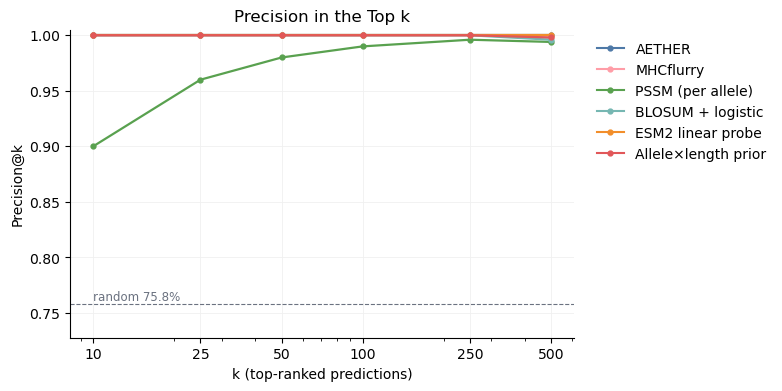

In [5]:
KS = [10, 25, 50, 100, 250, 500]

fig, ax = new_fig((6.5, 4))
base, lowest = None, 1.0
for m in show:
    d = preds[m].dropna(subset=["y_pred_prob"])
    yt = (d["y_true"] >= 0.5).astype(int).to_numpy()
    s = d["y_pred_prob"].to_numpy()
    base = yt.mean() if base is None else base
    ranked = yt[np.argsort(-s, kind="stable")]
    ks = [k for k in KS if k <= len(ranked)]
    prec = [ranked[:k].mean() for k in ks]
    lowest = min(lowest, min(prec))
    ax.plot(ks, prec, marker="o", markersize=3.5, linewidth=1.6,
            color=mcolor(m), label=mlabel(m))

if base is not None:
    ax.axhline(base, color=REF_LINE, linestyle="--", linewidth=0.8)
    ax.text(KS[0], base + 0.004, f"random {base:.1%}", fontsize=8.5, color=REF_LINE)

ax.set_xscale("log")
ax.set_xticks(KS, [str(k) for k in KS])
ax.set_xlabel("k (top-ranked predictions)")
ax.set_ylabel("Precision@k")
# Zoom to where the curves actually are. At a 77% base rate every method sits
# near the top, and a 0-1 axis would show nothing but a flat band.
ax.set_ylim(min(lowest, base if base else 1.0) - 0.03, 1.005)
ax.set_title("Precision in the Top k")
left_legend(ax, [plt.Line2D([], [], color=mcolor(m), marker="o", markersize=3.5,
                            label=mlabel(m)) for m in show], "", (1.02, 1.0))

save_fig(fig, "benchmark_precision_at_k.png")
plt.show()

## Per-Allele: AETHER vs the Strongest Baseline

A pooled number can hide a model that wins on the common alleles and loses
everywhere else. Each point is one allele; above the diagonal means AETHER wins
on it.

59 alleles with >= 100 rows and both classes


saved /home/vivian.chu/AETHER/figures/benchmark_per_allele.png


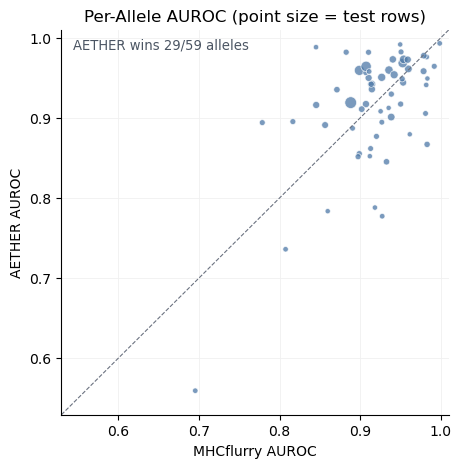

,allele,n,aether,base
0,HLA-B*27:03,185,0.9930,0.9986
1,HLA-B*27:06,122,0.9916,0.9496
2,HLA-C*07:02,146,0.9882,0.8451
3,HLA-C*04:01,279,0.9823,0.9506
4,HLA-A*02:04,333,0.9819,0.8825
5,HLA-B*27:02,315,0.9818,0.9103
6,HLA-B*40:01,481,0.9776,0.9789
7,HLA-B*39:01,215,0.9760,0.9824
8,HLA-B*15:01,1226,0.9730,0.9539
9,HLA-B*58:01,757,0.9730,0.9404


In [6]:
CHALLENGER = "aether"
baseline_name = next((m for m in order if m != CHALLENGER), None)

if CHALLENGER not in preds:
    print(f"No '{CHALLENGER}' predictions in {BENCH_DIR} — "
          "add them with --include aether=<path to test_predictions.csv>.")
elif baseline_name is None or "mhc_allele" not in preds[CHALLENGER].columns:
    print("Need an allele column and at least one other method for this plot.")
else:
    MIN_ROWS = 100
    # Pair the two score columns row-for-row, then drop rows either method
    # declined. A method that cannot score a row (MHCflurry skips peptides
    # outside 8-15mers) leaves NaN, and both sides must be compared on the
    # same rows for the diagonal to mean anything.
    a, b = preds[CHALLENGER], preds[baseline_name]
    paired = pd.DataFrame({
        "mhc_allele": a["mhc_allele"].to_numpy(),
        "y_true": a["y_true"].to_numpy(),
        "s_a": a["y_pred_prob"].to_numpy(),
        "s_b": b["y_pred_prob"].to_numpy(),
    }).dropna(subset=["s_a", "s_b"])

    rows = []
    for allele, g in paired.groupby("mhc_allele"):
        yg = (g["y_true"] >= 0.5).astype(int)
        if len(g) < MIN_ROWS or yg.nunique() < 2:
            continue
        rows.append({"allele": allele, "n": len(g),
                     "aether": roc_auc_score(yg, g["s_a"]),
                     "base": roc_auc_score(yg, g["s_b"])})
    pa = pd.DataFrame(rows)
    print(f"{len(pa)} alleles with >= {MIN_ROWS} rows and both classes")

    if len(pa):
        fig, ax = new_fig((5, 5))
        lim = [min(pa[["aether", "base"]].min()) - 0.03, 1.01]
        ax.plot(lim, lim, color=REF_LINE, linestyle="--", linewidth=0.8)
        sizes = 12 + 60 * pa["n"] / pa["n"].max()
        ax.scatter(pa["base"], pa["aether"], s=sizes, color=TAB["blue"],
                   alpha=0.75, edgecolor="white", linewidth=0.6)
        wins = int((pa["aether"] > pa["base"]).sum())
        ax.text(0.03, 0.95, f"AETHER wins {wins}/{len(pa)} alleles",
                transform=ax.transAxes, fontsize=9.5, color=BAR_COLOR)
        ax.set_xlabel(f"{mlabel(baseline_name)} AUROC")
        ax.set_ylabel("AETHER AUROC")
        ax.set_xlim(lim); ax.set_ylim(lim)
        ax.set_title("Per-Allele AUROC (point size = test rows)")
        save_fig(fig, "benchmark_per_allele.png")
        plt.show()
        display(pa.sort_values("aether", ascending=False).round(4).reset_index(drop=True))

## Summary Table

In [7]:
cols = [c for c in ("auroc_common", "auprc_common", "auroc", "auprc",
                    "coverage", "n_scored") if c in summary.columns]
out = summary.loc[order, cols].copy()
out.index = [mlabel(m) for m in order]
out.round(4)

,auroc_common,auprc_common,auroc,auprc,coverage,n_scored
AETHER,0.9640,0.9875,0.9639,0.9877,1.0000,35339.0
MHCflurry,0.9410,0.9803,0.9410,0.9803,0.9848,34803.0
PSSM (per allele),0.9178,0.9713,0.9107,0.9696,1.0000,35339.0
BLOSUM + logistic,0.8679,0.9511,0.8677,0.9517,1.0000,35339.0
ESM2 linear probe,0.8662,0.9517,0.8673,0.9528,1.0000,35339.0
Allele×length prior,0.8594,0.9504,0.8619,0.9521,1.0000,35339.0
Allele prior,0.8178,0.9291,0.8186,0.9304,1.0000,35339.0
PepMHC (archived),0.6122,0.7994,0.6149,0.8036,1.0000,35339.0
Majority class,0.5000,0.7547,0.5000,0.7577,1.0000,35339.0
